In [ ]:
pip install optuna

In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 41.6 MB/s  0:00:02


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import confusion_matrix, classification_report
from scipy import stats

from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
data=pd.read_csv("application.csv")
data.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
data.describe(include='all')

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511,307511,307511,307511,307511.000000,3.075110e+05,3.075110e+05,307499.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
unique,NaN,NaN,2,3,2,2,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Cash loans,F,N,Y,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,278232,202448,202924,213312,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,278180.518577,0.080729,NaN,NaN,NaN,NaN,0.417052,1.687979e+05,5.990260e+05,27108.573909,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,NaN,NaN,NaN,NaN,0.722121,2.371231e+05,4.024908e+05,14493.737315,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,2.565000e+04,4.500000e+04,1615.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,NaN,NaN,NaN,NaN,0.000000,1.125000e+05,2.700000e+05,16524.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,1.471500e+05,5.135310e+05,24903.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,NaN,NaN,NaN,NaN,1.000000,2.025000e+05,8.086500e+05,34596.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000


In [ ]:
data.isnull().sum()

,0
SK_ID_CURR,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
...,...
AMT_REQ_CREDIT_BUREAU_DAY,41519
AMT_REQ_CREDIT_BUREAU_WEEK,41519
AMT_REQ_CREDIT_BUREAU_MON,41519
AMT_REQ_CREDIT_BUREAU_QRT,41519


In [ ]:
for i in data.columns:
    if data[i].isnull().sum()/len(data)>0.1:
        data=data.drop(i,axis=1)

In [ ]:
data.isnull().sum()

,0
SK_ID_CURR,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
...,...
FLAG_DOCUMENT_17,0
FLAG_DOCUMENT_18,0
FLAG_DOCUMENT_19,0
FLAG_DOCUMENT_20,0


In [ ]:
data.drop('SK_ID_CURR',axis=1,inplace=True)

In [ ]:
data_lr,data_lr_test=train_test_split(data,test_size=0.3,random_state=42)

In [ ]:
for i in data_lr.columns:
    if data_lr[i].dtype=='object':
        fill_value=data_lr[i].mode()[0]
    else:
        fill_value=data_lr[i].mean()
    data_lr[i]=data_lr[i].fillna(fill_value)
    if i in data_lr_test.columns:
        data_lr_test[i]=data_lr_test[i].fillna(fill_value)

In [ ]:
data_lr.isnull().sum()

,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
...,...
FLAG_DOCUMENT_17,0
FLAG_DOCUMENT_18,0
FLAG_DOCUMENT_19,0
FLAG_DOCUMENT_20,0


In [ ]:


epsilon = 1e-6

woe_train = {}
woe_test = {}

for i in data_lr.columns:
    if i != 'TARGET':
        if data_lr[i].dtype != object:

            q1 = data_lr[i].quantile(0.25)
            q2 = data_lr[i].quantile(0.5)
            q3 = data_lr[i].quantile(0.75)

            ranges = sorted(set([-np.inf, q1, q2, q3, np.inf]))
            category_train = pd.cut(data_lr[i], bins=ranges)
            category_test = pd.cut(data_lr_test[i], bins=ranges)

            grouped = data_lr.groupby([category_train, 'TARGET'], observed=False)['TARGET'].count().unstack(fill_value=0).reset_index()


            grouped[0] = grouped[0].replace(0, epsilon)
            grouped[1] = grouped[1].replace(0, epsilon)


            grouped['positive_prop'] = grouped[0] / grouped[0].sum()
            grouped['negative_prop'] = grouped[1] / grouped[1].sum()


            grouped['woe'] = np.log(grouped['positive_prop'] / grouped['negative_prop'])

            grouped.rename(columns={'woe': i + '_woe'}, inplace=True)

            woe_map = dict(zip(grouped[i], grouped[i + '_woe']))
            woe_train[i + '_woe'] = category_train.map(woe_map).astype(float)
            woe_test[i + '_woe'] = category_test.map(woe_map).astype(float)

        else:
            grouped = data_lr.groupby([i, 'TARGET'])['TARGET'].count().unstack(fill_value=0).reset_index()

            grouped[0] = grouped[0].replace(0, epsilon)
            grouped[1] = grouped[1].replace(0, epsilon)

            grouped['positive_prop'] = grouped[0] / grouped[0].sum()
            grouped['negative_prop'] = grouped[1] / grouped[1].sum()

            grouped['woe'] = np.log(grouped['positive_prop'] / grouped['negative_prop'])

            grouped.rename(columns={'woe': i + '_woe'}, inplace=True)

            woe_map = dict(zip(grouped[i], grouped[i + '_woe']))
            woe_train[i + '_woe'] = data_lr[i].map(woe_map).astype(float)
            woe_test[i + '_woe'] = data_lr_test[i].map(woe_map).fillna(0).astype(float)

data_lr = pd.concat([data_lr, pd.DataFrame(woe_train)], axis=1)
data_lr_test = pd.concat([data_lr_test, pd.DataFrame(woe_test)], axis=1)


In [ ]:
data_lr.isnull().sum()

,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
...,...
FLAG_DOCUMENT_17_woe,0
FLAG_DOCUMENT_18_woe,0
FLAG_DOCUMENT_19_woe,0
FLAG_DOCUMENT_20_woe,0


In [ ]:

for i in data_lr.columns:
    if data_lr[i].dtype in ['int64', 'float64']:
        kstest_statistic, kstest_p_value = stats.kstest((data_lr[i] - data_lr[i].mean()) / data_lr[i].std(), 'norm')
        print(f'Column: {i}')
        print(f'Kolmogorov-Smirnov Test:')
        print(f'Test Statistic: {kstest_statistic}')
        print(f'p-value: {kstest_p_value}')

        if kstest_p_value > 0.05:
            print('Data looks normally distributed')
            print()
        else:
            print('Data does not look normally distributed')
            print()

Column: TARGET
Kolmogorov-Smirnov Test:
Test Statistic: 0.5357480617453277
p-value: 0.0
Data does not look normally distributed

Column: CNT_CHILDREN
Kolmogorov-Smirnov Test:
Test Statistic: 0.41882320926033767
p-value: 0.0
Data does not look normally distributed

Column: AMT_INCOME_TOTAL
Kolmogorov-Smirnov Test:
Test Statistic: 0.15774320034858247
p-value: 0.0
Data does not look normally distributed

Column: AMT_CREDIT
Kolmogorov-Smirnov Test:
Test Statistic: 0.10983696873441368
p-value: 0.0
Data does not look normally distributed

Column: AMT_ANNUITY
Kolmogorov-Smirnov Test:
Test Statistic: 0.07930508172173023
p-value: 0.0
Data does not look normally distributed

Column: AMT_GOODS_PRICE
Kolmogorov-Smirnov Test:
Test Statistic: 0.14223598833987106
p-value: 0.0
Data does not look normally distributed

Column: REGION_POPULATION_RELATIVE
Kolmogorov-Smirnov Test:
Test Statistic: 0.11390127265348665
p-value: 0.0
Data does not look normally distributed

Column: DAYS_BIRTH
Kolmogorov-Smirnov

In [ ]:
def target_correlation(data, target, threshold=0.01):

    woe_features = data.filter(regex='_woe$', axis=1).copy()
    woe_features[target] = data[target]

    corr_matrix = woe_features.corr(method='spearman')

    target_correlations = corr_matrix[target].abs() > threshold

    variables_explaining_target = target_correlations[target_correlations].index.tolist()

    variables_explaining_target.remove(target)

    result_explaining_target = pd.DataFrame(
    {'Variable': variables_explaining_target,
    'Correlation with Target': corr_matrix.loc[variables_explaining_target, target]})

    result_explaining_target.reset_index(drop=True, inplace=True)

    return result_explaining_target


target_result = target_correlation(data_lr, 'TARGET')

target_result

,Variable,Correlation with Target
0,NAME_CONTRACT_TYPE_woe,-0.031617
1,CODE_GENDER_woe,-0.054883
2,FLAG_OWN_CAR_woe,-0.022976
3,CNT_CHILDREN_woe,-0.021018
4,AMT_INCOME_TOTAL_woe,-0.020369
5,AMT_CREDIT_woe,-0.052200
6,AMT_ANNUITY_woe,-0.034630
7,AMT_GOODS_PRICE_woe,-0.066549
8,NAME_INCOME_TYPE_woe,-0.061716
9,NAME_EDUCATION_TYPE_woe,-0.055011


In [ ]:
def intercorrelation(data, target, threshold=0.7):

    woe_features = data.filter(regex='_woe$', axis=1)

    corr_matrix = woe_features.corr(method='spearman')

    highly_correlated_variables = (np.abs(corr_matrix) > threshold) & (corr_matrix != 1.0)

    independent_variable_pairs = np.where(highly_correlated_variables)

    correlated_pairs_set = set()

    for var1, var2 in zip(independent_variable_pairs[0], independent_variable_pairs[1]):

        if var1 < var2:
            correlated_pairs_set.add((corr_matrix.index[var1], corr_matrix.columns[var2]))
        else:
            correlated_pairs_set.add((corr_matrix.index[var2], corr_matrix.columns[var1]))

    result_intercorrelated_independent = pd.DataFrame(list(correlated_pairs_set), columns=['Variable 1', 'Variable 2'])

    return result_intercorrelated_independent


intercorrelated_result = intercorrelation(data_lr, 'TARGET')
intercorrelated_result

,Variable 1,Variable 2
0,REG_CITY_NOT_WORK_CITY_woe,LIVE_CITY_NOT_WORK_CITY_woe
1,REG_REGION_NOT_WORK_REGION_woe,LIVE_REGION_NOT_WORK_REGION_woe
2,DEF_30_CNT_SOCIAL_CIRCLE_woe,DEF_60_CNT_SOCIAL_CIRCLE_woe
3,REGION_RATING_CLIENT_woe,REGION_RATING_CLIENT_W_CITY_woe
4,CNT_CHILDREN_woe,CNT_FAM_MEMBERS_woe


In [ ]:
target_result.Variable.tolist()

['NAME_CONTRACT_TYPE_woe',
 'CODE_GENDER_woe',
 'FLAG_OWN_CAR_woe',
 'CNT_CHILDREN_woe',
 'AMT_INCOME_TOTAL_woe',
 'AMT_CREDIT_woe',
 'AMT_ANNUITY_woe',
 'AMT_GOODS_PRICE_woe',
 'NAME_INCOME_TYPE_woe',
 'NAME_EDUCATION_TYPE_woe',
 'NAME_FAMILY_STATUS_woe',
 'NAME_HOUSING_TYPE_woe',
 'REGION_POPULATION_RELATIVE_woe',
 'DAYS_BIRTH_woe',
 'DAYS_EMPLOYED_woe',
 'DAYS_REGISTRATION_woe',
 'DAYS_ID_PUBLISH_woe',
 'FLAG_WORK_PHONE_woe',
 'FLAG_PHONE_woe',
 'CNT_FAM_MEMBERS_woe',
 'REGION_RATING_CLIENT_woe',
 'REGION_RATING_CLIENT_W_CITY_woe',
 'HOUR_APPR_PROCESS_START_woe',
 'REG_CITY_NOT_LIVE_CITY_woe',
 'REG_CITY_NOT_WORK_CITY_woe',
 'LIVE_CITY_NOT_WORK_CITY_woe',
 'ORGANIZATION_TYPE_woe',
 'EXT_SOURCE_2_woe',
 'DEF_30_CNT_SOCIAL_CIRCLE_woe',
 'DEF_60_CNT_SOCIAL_CIRCLE_woe',
 'DAYS_LAST_PHONE_CHANGE_woe',
 'FLAG_DOCUMENT_3_woe',
 'FLAG_DOCUMENT_6_woe',
 'FLAG_DOCUMENT_13_woe',
 'FLAG_DOCUMENT_16_woe']

In [ ]:
corr_with_target = target_result.set_index('Variable')['Correlation with Target'].abs()
weaker_variables = [min(pair, key=lambda v: corr_with_target.get(v, 0)) for pair in zip(intercorrelated_result['Variable 1'], intercorrelated_result['Variable 2'])]
selected_woe = [v for v in target_result.Variable.tolist() if v not in weaker_variables]
data_lr_woe=data_lr[selected_woe+['TARGET']]
data_lr_test_woe=data_lr_test[selected_woe+['TARGET']]
data_lr_woe

,NAME_CONTRACT_TYPE_woe,CODE_GENDER_woe,FLAG_OWN_CAR_woe,CNT_CHILDREN_woe,AMT_INCOME_TOTAL_woe,AMT_CREDIT_woe,AMT_ANNUITY_woe,AMT_GOODS_PRICE_woe,NAME_INCOME_TYPE_woe,NAME_EDUCATION_TYPE_woe,...,REG_CITY_NOT_WORK_CITY_woe,ORGANIZATION_TYPE_woe,EXT_SOURCE_2_woe,DEF_30_CNT_SOCIAL_CIRCLE_woe,DAYS_LAST_PHONE_CHANGE_woe,FLAG_DOCUMENT_3_woe,FLAG_DOCUMENT_6_woe,FLAG_DOCUMENT_13_woe,FLAG_DOCUMENT_16_woe,TARGET
127044,-0.037133,0.154907,-0.059143,0.051990,-0.056443,-0.142692,0.119093,0.075955,0.068972,0.430282,...,0.105491,0.161941,0.299982,0.041711,0.065161,-0.100667,-0.031851,-0.002299,-0.004444,0
281143,-0.037133,0.154907,0.123313,-0.110133,-0.061501,-0.142692,-0.154270,-0.338845,-0.183804,-0.110670,...,0.105491,-0.157985,0.785387,0.041711,0.065161,-0.100667,-0.031851,-0.002299,-0.004444,1
199799,-0.037133,-0.251079,0.123313,-0.110133,0.173637,0.293385,-0.154270,0.075955,-0.183804,-0.110670,...,0.105491,-0.245370,0.785387,0.041711,-0.175627,-0.100667,-0.031851,-0.002299,-0.004444,0
306749,0.425427,0.154907,-0.059143,-0.119445,-0.061501,0.119792,0.154743,0.013617,0.068972,-0.110670,...,0.105491,-0.463303,-0.639150,0.041711,-0.154878,0.289846,-0.031851,-0.002299,-0.004444,0
301347,-0.037133,0.154907,-0.059143,0.051990,-0.034407,-0.142692,0.119093,0.075955,0.432573,-0.110670,...,0.105491,0.429735,0.000705,0.041711,-0.175627,0.289846,0.394802,-0.002299,-0.004444,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,-0.037133,0.154907,-0.059143,0.051990,-0.061501,-0.142692,-0.154270,0.075955,-0.183804,-0.110670,...,0.105491,-0.245370,0.299982,0.041711,-0.154878,-0.100667,-0.031851,-0.002299,-0.004444,0
259178,-0.037133,0.154907,-0.059143,-0.119445,0.173637,-0.206185,0.119093,0.075955,0.068972,-0.110670,...,0.105491,-0.181359,0.785387,0.041711,0.065161,-0.100667,-0.031851,-0.002299,-0.004444,0
131932,-0.037133,-0.251079,0.123313,0.051990,0.173637,0.293385,-0.154270,0.367998,-0.183804,0.430282,...,0.105491,-0.245370,0.299982,0.041711,0.334221,0.289846,-0.031851,-0.002299,-0.004444,0
146867,0.425427,-0.251079,0.123313,-0.110133,-0.056443,0.119792,0.154743,-0.338845,-0.183804,-0.110670,...,-0.297858,-0.064081,0.299982,0.041711,-0.175627,0.289846,-0.031851,-0.002299,-0.004444,0


In [ ]:
data_cat=data.copy()

In [ ]:
data.describe(include='all')

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
count,307511.000000,307511,307511,307511,307511,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,...,307511.000000,307511.000000,307511.000000,307511.00000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000
unique,NaN,2,3,2,2,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Cash loans,F,N,Y,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,278232,202448,202924,213312,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.080729,NaN,NaN,NaN,NaN,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,...,0.000007,0.003525,0.002936,0.00121,0.009928,0.000267,0.008130,0.000595,0.000507,0.000335
std,0.272419,NaN,NaN,NaN,NaN,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,...,0.002550,0.059268,0.054110,0.03476,0.099144,0.016327,0.089798,0.024387,0.022518,0.018299
min,0.000000,NaN,NaN,NaN,NaN,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,NaN,NaN,NaN,NaN,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,NaN,NaN,NaN,NaN,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,NaN,NaN,NaN,NaN,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
data=pd.get_dummies(data,drop_first=True,dtype='int')
data.head()

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
0,1,0,202500.0,406597.5,24700.5,351000.0,0.018801,-9461,-637,-3648.0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,270000.0,1293502.5,35698.5,1129500.0,0.003541,-16765,-1188,-1186.0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,67500.0,135000.0,6750.0,135000.0,0.010032,-19046,-225,-4260.0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,135000.0,312682.5,29686.5,297000.0,0.008019,-19005,-3039,-9833.0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,121500.0,513000.0,21865.5,513000.0,0.028663,-19932,-3038,-4311.0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
data.describe(include='all')

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
count,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000
mean,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,-4986.120328,...,0.000208,0.000159,0.002052,0.025466,0.000654,0.007167,0.003860,0.017554,0.004315,0.180072
std,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,3522.886321,...,0.014425,0.012622,0.045252,0.157535,0.025558,0.084356,0.062009,0.131323,0.065549,0.384248
min,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,-7479.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,-4504.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,-2010.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
data_rf=data.copy()

In [ ]:
data_cat.isnull().sum()

,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
...,...
FLAG_DOCUMENT_17,0
FLAG_DOCUMENT_18,0
FLAG_DOCUMENT_19,0
FLAG_DOCUMENT_20,0


In [ ]:
a=[]
for i in data_cat.columns:
    if data_cat[i].dtype=='object':
        a.append(i)

In [ ]:
a

['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE']

In [ ]:
for i in a:
    data_cat[i]=data_cat[i].fillna('missing_value')

In [ ]:
x=data.drop('TARGET',axis=1)
y=data['TARGET']
x_cat=data_cat.drop('TARGET',axis=1)
x_rf=data_rf.drop('TARGET',axis=1)

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
x_train_cat,x_test_cat,y_train_cat,y_test_cat=train_test_split(x_cat,y,test_size=0.3,random_state=42)
x_train_rf,x_test_rf,y_train_rf,y_test_rf=train_test_split(x_rf,y,test_size=0.3,random_state=42)
x_train_lr, y_train_lr = data_lr_woe.drop('TARGET', axis=1), data_lr_woe['TARGET']
x_test_lr, y_test_lr = data_lr_test_woe.drop('TARGET', axis=1), data_lr_test_woe['TARGET']

In [ ]:
for i in x_train_rf:
    if x_train_rf[i].dtype=='object':
        fill_value=x_train_rf[i].mode()[0]
    else:
        fill_value=x_train_rf[i].mean()
    x_train_rf[i]=x_train_rf[i].fillna(fill_value)
    x_test_rf[i]=x_test_rf[i].fillna(fill_value)

In [ ]:
def clean_column_names(df):
    df.columns = df.columns.str.replace(r'[^\w\d_]', '_', regex=True)
    return df

x_train = clean_column_names(x_train)
x_test=clean_column_names(x_test)

In [ ]:
models=[]
xgb_model_def = XGBClassifier(random_state=42)
lgb_model_def = LGBMClassifier(random_state=42)
catboost_model_def = CatBoostClassifier(random_state=42)
catboost_model_custom = CatBoostClassifier(cat_features=a, random_state=42)
random_forest=RandomForestClassifier(random_state=42)
logistic_regression = LogisticRegression()

models.extend([
    ('XGBoost', xgb_model_def),
    ('LightGBM', lgb_model_def),
    ('CatBoost', catboost_model_def),
    ('CatBoost_Custom', catboost_model_custom),
    ('RandomForest',random_forest),
    ('LogisticRegression',logistic_regression)
])

In [ ]:
def train_and_evaluate_model(model_name, model, X_train, y_train, X_test, y_test):
    try:
        model.fit(X_train, y_train)

        y_pred_train = model.predict(X_train)
        y_prob_train = model.predict_proba(X_train)[:, 1]

        roc_prob_train = roc_auc_score(y_train, y_prob_train)
        gini_prob_train = roc_prob_train * 2 - 1
        confusion_matrix_result_train = confusion_matrix(y_train, y_pred_train)
        classification_report_result_train = classification_report(y_train, y_pred_train, zero_division=0)

        print(f'Model Performance for {model_name}')
        print('Train Gini prob is', gini_prob_train * 100)
        print(classification_report_result_train)
        print(confusion_matrix_result_train)

        y_pred_test = model.predict(X_test)
        y_prob_test = model.predict_proba(X_test)[:, 1]

        roc_prob_test = roc_auc_score(y_test, y_prob_test)
        gini_prob_test = roc_prob_test * 2 - 1
        confusion_matrix_result_test = confusion_matrix(y_test, y_pred_test)
        classification_report_result_test = classification_report(y_test, y_pred_test, zero_division=0)

        print(f'Model Performance for {model_name}')
        print('Test Gini prob is', gini_prob_test * 100)
        print(classification_report_result_test)
        print(confusion_matrix_result_test)

        return [gini_prob_train, gini_prob_test]

    except Exception as e:
        print(f"An error occurred while evaluating the model {model_name}: {e}")
        return None


In [ ]:
gini_df = pd.DataFrame(columns=['Model', 'Train Gini', 'Test Gini'])

for model_name, model in models:
    if model_name == 'CatBoost_Custom':
        gini_prob = train_and_evaluate_model(model_name, model, x_train_cat, y_train_cat, x_test_cat, y_test_cat)
    elif model_name=='RandomForest':
        gini_prob=train_and_evaluate_model(model_name, model, x_train_rf, y_train_rf, x_test_rf, y_test_rf)
    elif model_name=='LogisticRegression':
        gini_prob=train_and_evaluate_model(model_name, model, x_train_lr, y_train_lr, x_test_lr, y_test_lr)
    else:
        gini_prob = train_and_evaluate_model(model_name, model, x_train, y_train, x_test, y_test)

    if gini_prob is not None:
        gini_df = pd.concat([gini_df, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)

gini_df_sorted = gini_df.sort_values(by='Test Gini', ascending=False)

gini_df_sorted

Model Performance for XGBoost
Train Gini prob is 67.00633457133974
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    197845
           1       0.82      0.04      0.07     17412

    accuracy                           0.92    215257
   macro avg       0.87      0.52      0.52    215257
weighted avg       0.91      0.92      0.89    215257

[[197703    142]
 [ 16756    656]]
Model Performance for XGBoost
Test Gini prob is 42.4133244234822
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     84841
           1       0.41      0.02      0.03      7413

    accuracy                           0.92     92254
   macro avg       0.67      0.51      0.49     92254
weighted avg       0.88      0.92      0.88     92254

[[84667   174]
 [ 7292   121]]


/tmp/ipykernel_4868/3050119926.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  gini_df = pd.concat([gini_df, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)


[LightGBM] [Info] Number of positive: 17412, number of negative: 197845
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.120794 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2890
[LightGBM] [Info] Number of data points in the train set: 215257, number of used features: 137
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080889 -> initscore=-2.430324
[LightGBM] [Info] Start training from score -2.430324
Model Performance for LightGBM
Train Gini prob is 54.27598773522588
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    197845
           1       0.74      0.01      0.02     17412

    accuracy                           0.92    215257
   macro avg       0.83      0.50      0.49    215257
weighted avg       0.90      0.92      0.88    215257

[[197793     52]
 [ 17266    146]]
Model Per

,Model,Train Gini,Test Gini
3,CatBoost_Custom,0.593317,0.448678
2,CatBoost,0.629505,0.446013
1,LightGBM,0.542760,0.442454
0,XGBoost,0.670063,0.424133
5,LogisticRegression,0.404244,0.399704
4,RandomForest,1.000000,0.359185


In [ ]:
def best_params_for_model(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100)
    }

    lgb_clf = LGBMClassifier(**param, random_state=42)

    auc = cross_val_score(lgb_clf, x_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc

study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=10)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_lgb_model = LGBMClassifier(**best_params, random_state=42)

[I 2026-11-11 12:45:05,722] A new study created in memory with name: no-name-d3fd5bc9-821e-4a04-8747-93846e292c50
[I 2026-11-11 12:46:25,306] Trial 0 finished with value: 0.7147035650165364 and parameters: {'n_estimators': 731, 'learning_rate': 0.03093111384968796, 'max_depth': 7, 'num_leaves': 63}. Best is trial 0 with value: 0.7147035650165364.
[I 2026-11-11 12:47:04,468] Trial 1 finished with value: 0.7171595303977591 and parameters: {'n_estimators': 480, 'learning_rate': 0.043996428096179166, 'max_depth': 6, 'num_leaves': 31}. Best is trial 1 with value: 0.7171595303977591.
[I 2026-11-11 12:47:45,943] Trial 2 finished with value: 0.7052615405755938 and parameters: {'n_estimators': 517, 'learning_rate': 0.12830241718195176, 'max_depth': 10, 'num_leaves': 24}. Best is trial 1 with value: 0.7171595303977591.
[I 2026-11-11 12:48:32,193] Trial 3 finished with value: 0.7143233923582583 and parameters: {'n_estimators': 778, 'learning_rate': 0.013275008061452136, 'max_depth': 3, 'num_leave

Best trial:
  Value: 0.717
  Params:  {'n_estimators': 480, 'learning_rate': 0.043996428096179166, 'max_depth': 6, 'num_leaves': 31}


In [ ]:
def best_params_for_model(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_int('gamma', 0, 10)
    }

    xgb_clf = XGBClassifier(**param, random_state=42)
    auc = cross_val_score(xgb_clf, x_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=10)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_xgb_model = XGBClassifier(**best_params, random_state=42)

[I 2026-11-11 12:54:19,771] A new study created in memory with name: no-name-769be647-b51b-4f0a-b6fa-41d1371da9dd
/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[I 2026-11-11 12:55:09,909] Trial 0 finished with value: 0.7173642249017765 and parameters: {'n_estimators': 267, 'learning_rate': 0.025811653870244148, 'max_depth': 5, 'subsample': 0.6290540240460749, 'colsample_bytree': 0.6263353656358692, 'gamma': 0}. Best is trial 0 with value: 0.7173642249017765.
[I 2026-11-11 12:56:06,871] Trial 1 finished with value: 0.7172218832547629 and parameters: {'n_estimators': 471, 'learning_rate': 0.032509483067553684, 'max_depth': 9, 'subsample': 0.9006251930320309, 'colsample_bytree': 0.6053174467829008, 'gamma': 9}. Best is trial 0 with value: 0.7173642249017765.
[I 2026-11-11 12:56:21,785] Tria

Best trial:
  Value: 0.718
  Params:  {'n_estimators': 239, 'learning_rate': 0.0474155130115959, 'max_depth': 9, 'subsample': 0.6329588731408811, 'colsample_bytree': 0.9631768385281443, 'gamma': 7}


In [ ]:
def best_params_for_model(trial):

    param = {
        'iterations': trial.suggest_int('iterations', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0, log=True),
        'depth': trial.suggest_int('depth', 3, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 0.1, 10, log=True),
        'loss_function': trial.suggest_categorical('loss_function', ['Logloss'])
    }

    cb_clf = CatBoostClassifier(**param, random_state=42)

    auc = cross_val_score(cb_clf, x_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=3)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_cb_model = CatBoostClassifier(**best_params, random_state=42)

[I 2026-11-11 13:04:27,461] A new study created in memory with name: no-name-fa6273ce-75e0-4f3b-b776-dc4125475029
/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[I 2026-11-11 13:08:19,296] Trial 0 finished with value: 0.7176864327958309 and parameters: {'iterations': 920, 'learning_rate': 0.01880298896296093, 'depth': 9, 'l2_leaf_reg': 0.3305672915735758, 'loss_function': 'Logloss'}. Best is trial 0 with value: 0.7176864327958309.
[I 2026-11-11 13:08:57,078] Trial 1 finished with value: 0.7152050704170976 and parameters: {'iterations': 314, 'learning_rate': 0.05264508389345325, 'depth': 3, 'l2_leaf_reg': 4.7846838195054495, 'loss_function': 'Logloss'}. Best is trial 0 with value: 0.7176864327958309.
[I 2026-11-11 13:11:17,637] Trial 2 finished with value: 0.6723688696304492 and parameters

Best trial:
  Value: 0.718
  Params:  {'iterations': 920, 'learning_rate': 0.01880298896296093, 'depth': 9, 'l2_leaf_reg': 0.3305672915735758, 'loss_function': 'Logloss'}


In [ ]:
def best_params_for_model(trial):

    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
       'max_features': trial.suggest_float('max_features', 0.01, 1.0, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
      'min_samples_split': trial.suggest_int('min_samples_split', 20, 50),
    'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5,10)
    }

    rf_clf = RandomForestClassifier(**param, random_state=42)

    auc = cross_val_score(rf_clf, x_train_rf, y_train_rf, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=3)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_rf_model = RandomForestClassifier(**best_params, random_state=42)

[I 2026-11-11 13:45:34,953] A new study created in memory with name: no-name-f9d806fc-dc2b-4d4c-952b-d9dcdff04568
[I 2026-11-11 13:52:55,759] Trial 0 finished with value: 0.698325629927938 and parameters: {'n_estimators': 932, 'max_features': 0.0805682380868024, 'max_depth': 8, 'min_samples_split': 26, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.698325629927938.
[I 2026-11-11 13:53:26,695] Trial 1 finished with value: 0.6762280305341828 and parameters: {'n_estimators': 274, 'max_features': 0.02322875153089425, 'max_depth': 4, 'min_samples_split': 32, 'min_samples_leaf': 7}. Best is trial 0 with value: 0.698325629927938.
[I 2026-11-11 13:53:44,872] Trial 2 finished with value: 0.6737424320945681 and parameters: {'n_estimators': 149, 'max_features': 0.022521027797045748, 'max_depth': 4, 'min_samples_split': 39, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.698325629927938.


Best trial:
  Value: 0.698
  Params:  {'n_estimators': 932, 'max_features': 0.0805682380868024, 'max_depth': 8, 'min_samples_split': 26, 'min_samples_leaf': 10}


In [ ]:
variables = []
train_gini_scores = []
test_gini_scores = []


for i in x_train_lr.columns:
    X_train_single_var = x_train_lr[[i]]
    X_test_single_var = x_test_lr[[i]]


    logistic_regression.fit(X_train_single_var, y_train_lr)
    y_pred_train_single_var = logistic_regression.predict_proba(X_train_single_var)[:, 1]


    train_roc = roc_auc_score(y_train_lr, y_pred_train_single_var)


    train_gini = 2 * train_roc - 1


    y_pred_test_single_var = logistic_regression.predict_proba(X_test_single_var)[:, 1]


    test_roc = roc_auc_score(y_test_lr, y_pred_test_single_var)


    test_gini = 2 * test_roc - 1

    variables.append(i)
    train_gini_scores.append(train_gini)
    test_gini_scores.append(test_gini)

results_df = pd.DataFrame({
    'Variable': variables,
    'Train Gini': train_gini_scores,
    'Test Gini': test_gini_scores
})

results_df_sorted = results_df.sort_values(by='Train Gini', ascending=False)


pd.options.display.float_format = '{:.4f}'.format


results_df_sorted

,Variable,Train Gini,Test Gini
24,EXT_SOURCE_2_woe,0.2797,0.2905
13,DAYS_BIRTH_woe,0.1545,0.1549
23,ORGANIZATION_TYPE_woe,0.1510,0.1395
14,DAYS_EMPLOYED_woe,0.1486,0.1418
7,AMT_GOODS_PRICE_woe,0.1364,0.1275
8,NAME_INCOME_TYPE_woe,0.1200,0.1276
16,DAYS_ID_PUBLISH_woe,0.1081,0.1014
5,AMT_CREDIT_woe,0.1070,0.0945
26,DAYS_LAST_PHONE_CHANGE_woe,0.1043,0.1174
1,CODE_GENDER_woe,0.0955,0.0947


In [ ]:
selected_variables = results_df_sorted['Variable'].head(10).tolist()
x_train_final = x_train_lr[selected_variables]
x_test_final = x_test_lr[selected_variables]

In [ ]:
final_lr=LogisticRegression()

In [ ]:
models_optimized = []

models_optimized.extend([
    ('XGBoost Optuna', best_xgb_model),
    ('LightGBM Optuna', best_lgb_model),
    ('CatBoost Optuna', best_cb_model),
    ('RandomForest Optuna', best_rf_model),
    ('Logistic Regression Final',final_lr)
])

In [ ]:
gini_df_optuna = pd.DataFrame(columns=['Model', 'Train Gini', 'Test Gini'])

for model_name, model in models_optimized:
    if model_name=='RandomForest Optuna':
        gini_prob = train_and_evaluate_model(model_name, model, x_train_rf, y_train_rf, x_test_rf, y_test_rf)
    elif model_name=='Logistic Regression Final':
        gini_prob=train_and_evaluate_model(model_name, model, x_train_final, y_train_lr, x_test_final, y_test_lr)
    else:
        gini_prob = train_and_evaluate_model(model_name, model, x_train, y_train, x_test, y_test)
    if gini_prob is not None:
        gini_df_optuna = pd.concat([gini_df_optuna, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)

Model Performance for XGBoost Optuna
Train Gini prob is 58.352400138136716
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    197845
           1       0.87      0.01      0.02     17412

    accuracy                           0.92    215257
   macro avg       0.90      0.51      0.49    215257
weighted avg       0.92      0.92      0.88    215257

[[197814     31]
 [ 17198    214]]
Model Performance for XGBoost Optuna
Test Gini prob is 44.3639274363155
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     84841
           1       0.48      0.01      0.01      7413

    accuracy                           0.92     92254
   macro avg       0.70      0.50      0.48     92254
weighted avg       0.88      0.92      0.88     92254

[[84795    46]
 [ 7371    42]]


/tmp/ipykernel_4868/3350174141.py:11: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  gini_df_optuna = pd.concat([gini_df_optuna, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)


[LightGBM] [Info] Number of positive: 17412, number of negative: 197845
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.132442 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2890
[LightGBM] [Info] Number of data points in the train set: 215257, number of used features: 137
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080889 -> initscore=-2.430324
[LightGBM] [Info] Start training from score -2.430324
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [ ]:
gini_df_sorted_optuna = gini_df_optuna.sort_values(by='Test Gini', ascending=False)

gini_df_sorted_optuna

,Model,Train Gini,Test Gini
1,LightGBM Optuna,0.6009,0.4448
0,XGBoost Optuna,0.5835,0.4436
2,CatBoost Optuna,0.6026,0.4425
3,RandomForest Optuna,0.4546,0.3998
4,Logistic Regression Final,0.3690,0.3680


In [ ]:
final_review = pd.concat([gini_df_sorted,gini_df_sorted_optuna], axis=0)

final_review_sorted = final_review.sort_values(by='Test Gini', ascending=False)
final_review_sorted.reset_index(drop=True, inplace=True)

final_review_sorted

,Model,Train Gini,Test Gini
0,CatBoost_Custom,0.5933,0.4487
1,CatBoost,0.6295,0.4460
2,LightGBM Optuna,0.6009,0.4448
3,XGBoost Optuna,0.5835,0.4436
4,LightGBM,0.5428,0.4425
5,CatBoost Optuna,0.6026,0.4425
6,XGBoost,0.6701,0.4241
7,RandomForest Optuna,0.4546,0.3998
8,LogisticRegression,0.4042,0.3997
9,Logistic Regression Final,0.3690,0.3680


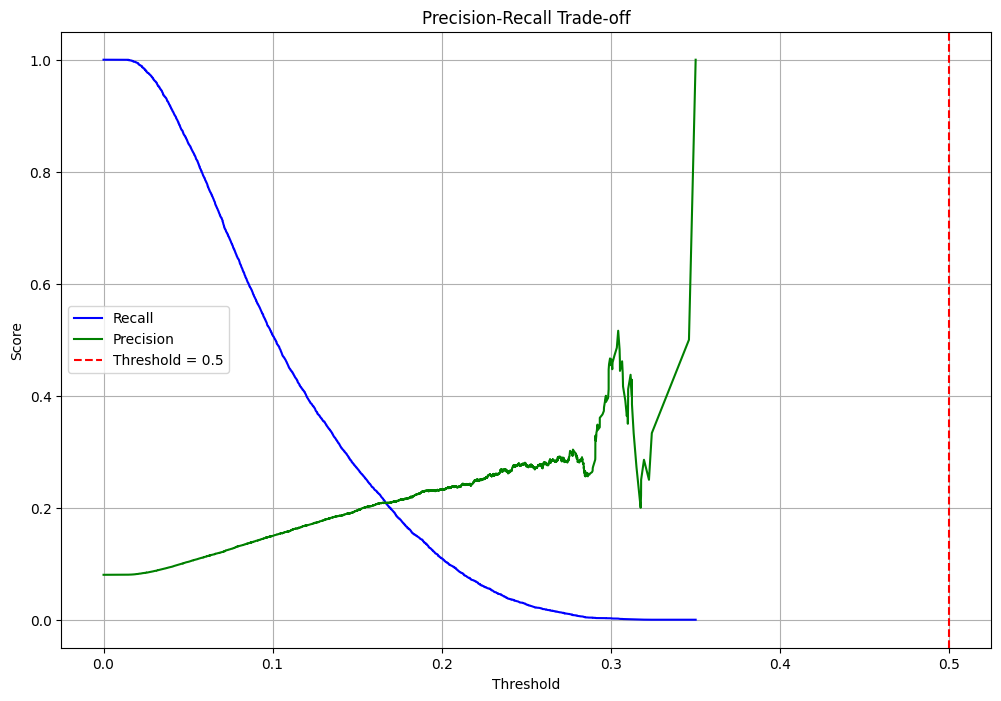

In [ ]:
y_prob = final_lr.predict_proba(x_test_final)[:,1]

precision, recall, thresholds = precision_recall_curve(y_test_lr, y_prob)

plt.figure(figsize=(12, 8))
plt.plot(thresholds, recall[:-1], label='Recall', color='blue')
plt.plot(thresholds, precision[:-1], label='Precision', color='green')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off')
plt.axvline(x=0.5, color='red', linestyle='--', label='Threshold = 0.5')
plt.legend()
plt.grid(True)
plt.show()

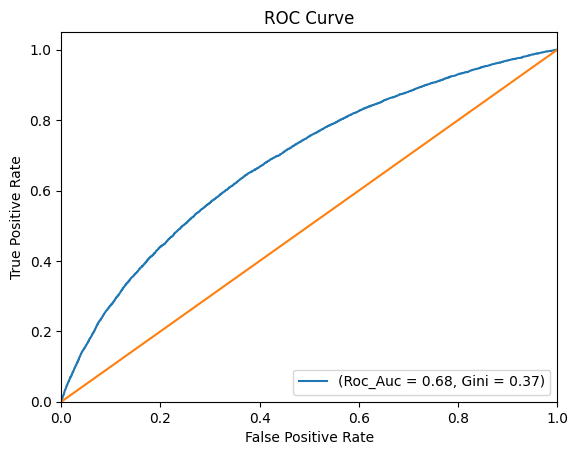

In [ ]:
y_prob = final_lr.predict_proba(x_test_final)[:,1]

roc_auc = roc_auc_score(y_test_lr, y_prob)
gini = (2*roc_auc_score(y_test_lr, y_prob))-1

fpr, tpr, thresholds = roc_curve(y_test_lr, y_prob)
plt.figure()

plt.plot(fpr, tpr, label='(Roc_Auc = %0.2f, Gini = %0.2f)' % (roc_auc, gini))
plt.plot([0, 1], [0, 1])
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend(loc='lower right')
plt.show()